In [ ]:
# Kiểm tra xem Colab đã nhận GPU T4 chưa
!nvidia-smi

# Cài đặt các thư viện cần thiết (thêm -q để ẩn log cài đặt cho gọn)
!pip install ultralytics mlflow dagshub -q

Sun Aug 16 09:50:12 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import drive
import os

# 1. Mount toàn bộ Drive
drive.mount('/content/drive')

# 2. Khai báo đường dẫn tới thư mục repo dự án của bạn trên Drive
# VÍ DỤ: Nếu thư mục dự án của bạn tên là "PPE_YOLOv8_Project" nằm ngoài cùng Drive
PROJECT_DIR = '/content/drive/MyDrive/ppe_cv'

# 3. Tạo thư mục nếu nó chưa tồn tại
if not os.path.exists(PROJECT_DIR):
    os.makedirs(PROJECT_DIR)
    print(f"Đã tạo thư mục mới: {PROJECT_DIR}")

# 4. Thay đổi thư mục làm việc hiện tại của Colab vào thư mục project
%cd {PROJECT_DIR}

print(f"✅ Đã trỏ môi trường làm việc vào: {os.getcwd()}")

Mounted at /content/drive
/content/drive/MyDrive/ppe_cv
✅ Đã trỏ môi trường làm việc vào: /content/drive/MyDrive/ppe_cv


In [ ]:
import os
import getpass
import mlflow
import torch
from ultralytics import YOLO
import shutil

Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
DAGSHUB_USER = input("Nhập DagsHub Username: ")
DAGSHUB_TOKEN = getpass.getpass("Nhập DagsHub Token: ")
DAGSHUB_REPO = input("Nhập tên DagsHub Repo (VD: ppe-project): ")

os.environ["MLFLOW_TRACKING_USERNAME"] = DAGSHUB_USER
os.environ["MLFLOW_TRACKING_PASSWORD"] = DAGSHUB_TOKEN
os.environ["MLFLOW_TRACKING_URI"] = f"https://dagshub.com/{DAGSHUB_USER}/{DAGSHUB_REPO}.mlflow"

mlflow.set_experiment("YOLOv8s_train_PPE_Baseline")
print("✅ Cấu hình MLflow thành công!")

Nhập DagsHub Username: TQanh23
Nhập DagsHub Token: ··········
Nhập tên DagsHub Repo (VD: ppe-project): ppe_v2
✅ Cấu hình MLflow thành công!


In [ ]:
torch.cuda.empty_cache()

model = YOLO("yolov8s.pt")

with mlflow.start_run(run_name="train_baseline_yolov8s"):
    results = model.train(
        data="/content/drive/MyDrive/ppe_cv/ppe_v2/data.yaml", # CHÚ Ý: Đổi thành đường dẫn thật trên Drive của bạn
        epochs=150,
        imgsz=640,
        batch=64,              # Đã tăng lên 16 nhờ VRAM 16GB của Colab
        workers=4,             # Bật lại workers=2 (Colab free thường có 2 nhân CPU)
        cache=False,
        amp=True,
        patience=30,
        project="/content/YOLOv8_Pruning", # Lưu tạm trên môi trường Colab
        name="baseline_run",
        save=True
    )

print("Huấn luyện hoàn tất!")

Ultralytics 8.4.120 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/ppe_cv/ppe_v2/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=150, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline_run, 

2026/08/16 10:06:24 WARNING mlflow.spark: With Pyspark >= 3.2, PYSPARK_PIN_THREAD environment variable must be set to false for Spark datasource autologging to work.
2026/08/16 10:06:24 INFO mlflow.tracking.fluent: Autologging successfully enabled for pyspark.


MLflow: logging run_id(e9164d43b53f4ed0bba777cbe94560c1) to https://dagshub.com/TQanh23/ppe_v2.mlflow
MLflow: disable with 'yolo settings mlflow=False'
Image sizes 640 train, 640 val
Using 2 dataloader workers
Logging results to /content/YOLOv8_Pruning/baseline_run
Starting training for 150 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      1/150      13.4G      1.886      2.895      1.577        812        640: 100% ━━━━━━━━━━━━ 33/33 1.3s/it 41.7s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.4s/it 6.7s
                   all        229       2019      0.438      0.397      0.362      0.159

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      2/150      12.9G      1.668      1.435      1.372        843        640: 100% ━━━━━━━━━━━━ 33/33 1.1s/it 35.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 10

In [ ]:
best_model_path = "/content/YOLOv8_Pruning/baseline_run/weights/best.pt"
trained_model = YOLO(best_model_path)
pytorch_model = trained_model.model

In [ ]:
pytorch_model.is_fused = lambda: True

def check_batchnorm_exists(model_to_check):
    bn_count = 0
    for module in model_to_check.modules():
        if isinstance(module, torch.nn.BatchNorm2d):
            bn_count += 1
            if hasattr(module, 'weight') and module.weight is not None:
                pass
    return bn_count

total_bn = check_batchnorm_exists(pytorch_model)

if total_bn > 0:
    print(f"✅ THÀNH CÔNG: Mô hình có chứa {total_bn} lớp BatchNorm2d.")

    # Copy file gốc sang Google Drive để lưu vĩnh viễn
    drive_save_path = "/content/drive/MyDrive/ppe_cv/best_baseline_yolov8s.pt"
    shutil.copy(best_model_path, drive_save_path)
    print(f"📁 Đã sao lưu checkpoint an toàn tại: {drive_save_path}")
else:
    print("❌ THẤT BẠI: Không tìm thấy BatchNorm2d. Mô hình đã bị fuse!")

✅ THÀNH CÔNG: Mô hình có chứa 57 lớp BatchNorm2d.
📁 Đã sao lưu checkpoint an toàn tại: /content/drive/MyDrive/ppe_cv/best_baseline_yolov8s.pt


In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
model_path = "/content/drive/MyDrive/ppe_cv/best_baseline_yolov8s.pt"
model = YOLO(model_path)

In [ ]:
print("Đang tiến hành đánh giá mô hình trên tập validation...")
# Chạy validation (mặc định dùng tập 'val' khai báo trong data.yaml)
metrics = model.val(data="/content/drive/MyDrive/ppe_cv/ppe_v2/data.yaml", split="test", batch=16)

# Trích xuất các chỉ số
map_50 = metrics.box.map50
map_50_95 = metrics.box.map
precision = metrics.box.mp  # Mean precision
recall = metrics.box.mr     # Mean recall

# Tính F1-Score từ Mean Precision và Mean Recall
f1_score = 2 * (precision * recall) / (precision + recall + 1e-16)

# Thời gian suy luận (Inference time per image tính bằng milliseconds)
inference_time = metrics.speed['inference']

# In kết quả
print("-" * 30)
print("KẾT QUẢ ĐÁNH GIÁ (BASELINE)")
print("-" * 30)
print(f"mAP@50       : {map_50:.4f}")
print(f"mAP@50-95    : {map_50_95:.4f}")
print(f"Precision    : {precision:.4f}")
print(f"Recall       : {recall:.4f}")
print(f"F1-Score     : {f1_score:.4f}")
print(f"Inference    : {inference_time:.2f} ms/image")
print("-" * 30)

Đang tiến hành đánh giá mô hình trên tập validation...
Ultralytics 8.4.120 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 11,129,067 parameters, 0 gradients, 28.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 1.7±1.0 ms, read: 13.8±10.8 MB/s, size: 78.5 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips/
val: Scanning /content/drive/MyDrive/ppe_cv/train_data/valid/labels.cache... 229 images, 19 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 229/229 60.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 2.4it/s 6.3s
                   all        229       2019      0.728       0.65      0.672      0.332
                 boots         93        201      0.683      0.547      0.569      0.222
                gloves         78        157      0.643      0.414      0.431   


Đang chạy dự đoán trên ảnh: /content/drive/MyDrive/ppe_cv/test_data/valid/images/YTDown_Shorts_Buoi-sang-soi-dong-tren-cong-truong-xay-_Media_WP5SFizRWhM_001_1080p_frame_0000_jpg.rf.81dfbfa0f8dd8e3c73160cbc302610f8.jpg

image 1/1 /content/drive/MyDrive/ppe_cv/test_data/valid/images/YTDown_Shorts_Buoi-sang-soi-dong-tren-cong-truong-xay-_Media_WP5SFizRWhM_001_1080p_frame_0000_jpg.rf.81dfbfa0f8dd8e3c73160cbc302610f8.jpg: 640x640 2 persons, 1 vest, 16.2ms
Speed: 1.8ms preprocess, 16.2ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/drive/MyDrive/ppe_cv/runs/detect/predict-3


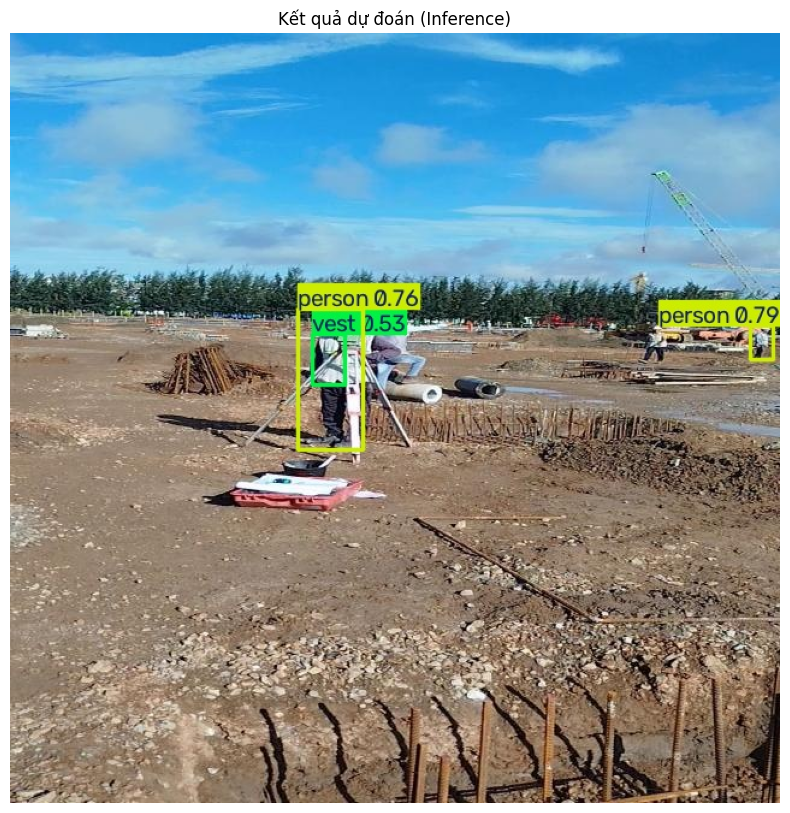

In [ ]:
test_image_path = "/content/drive/MyDrive/ppe_cv/test_data/valid/images/YTDown_Shorts_Buoi-sang-soi-dong-tren-cong-truong-xay-_Media_WP5SFizRWhM_001_1080p_frame_0000_jpg.rf.81dfbfa0f8dd8e3c73160cbc302610f8.jpg"

print(f"\nĐang chạy dự đoán trên ảnh: {test_image_path}")
# Chạy predict và lưu ảnh kết quả có vẽ bounding box
results = model.predict(source=test_image_path, save=True, conf=0.5)

# Lấy đường dẫn thư mục vừa lưu ảnh kết quả (thường là runs/detect/predict)
save_dir = results[0].save_dir
result_image_path = os.path.join(save_dir, os.path.basename(test_image_path))

# Hiển thị ảnh ngay trong Colab / Jupyter Notebook bằng Matplotlib
if os.path.exists(result_image_path):
    img = cv2.imread(result_image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) # Chuyển từ BGR (OpenCV) sang RGB (Matplotlib)

    plt.figure(figsize=(10, 10))
    plt.imshow(img)
    plt.axis('off')
    plt.title("Kết quả dự đoán (Inference)")
    plt.show()
else:
    print("Không tìm thấy ảnh kết quả. Hãy kiểm tra lại đường dẫn.")

In [ ]:
!python /content/drive/MyDrive/ppe_cv/ppe_v2/scripts/val.py \
    --weight /content/drive/MyDrive/ppe_cv/best_baseline_yolov8s.pt \
    --data data.yaml \
    --split val \
    --batch 16 \
    --imgsz 640

Average Latency per image: 10.74 ms
Approx FPS: 93.10
Ultralytics 8.4.120 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 11,129,067 parameters, 0 gradients, 28.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.6±0.4 ms, read: 49.7±31.8 MB/s, size: 71.1 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips/
val: Scanning /content/drive/MyDrive/ppe_cv/train_data/valid/labels.cache... 229 images, 19 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 229/229 31.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 2.8it/s 5.4s
                   all        229       2019      0.728       0.65      0.672      0.332
                 boots         93        201      0.683      0.547      0.569      0.222
                gloves         78        157      0.643      0.414      0.431    